# 💳 Loan Default Prediction

**Goal:** predict whether a credit-card customer will default next month, using their credit limit, age, payment history, bills and payments.

**Pipeline:** load data → explore → clean → split → scale → train Logistic Regression → evaluate → compare with Decision Tree → save for the Streamlit app.

## 📦 Step 1: Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, roc_auc_score)

TARGET = "default.payment.next.month"
RANDOM_STATE = 42

## 📊 Step 2: Load the Data

In [ ]:
df = pd.read_csv("loan.csv")
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


## 🔍 Step 3: Explore the Data

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   30000 non-null

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


### Missing values and duplicates

In [ ]:
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Total missing values: 0
Duplicate rows: 0


### Target balance
How many customers defaulted (1) vs paid (0)? Defaults are the minority, so accuracy alone can be misleading.

default.payment.next.month
0    23364
1     6636
Name: count, dtype: int64

Default rate: 22.1%


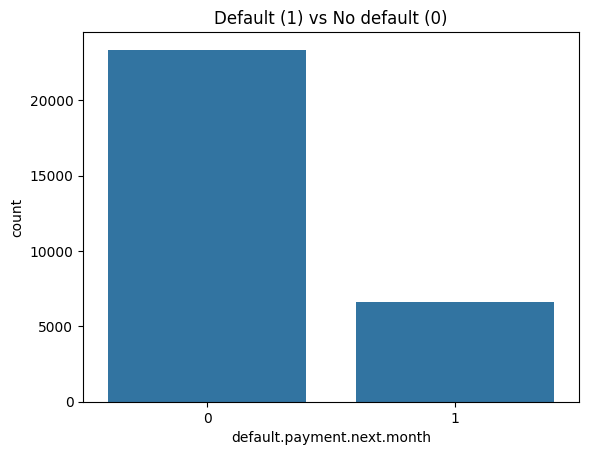

In [ ]:
counts = df[TARGET].value_counts()
print(counts)
print("\nDefault rate: {:.1%}".format(df[TARGET].mean()))

sns.countplot(x=TARGET, data=df)
plt.title("Default (1) vs No default (0)")
plt.show()

### Correlation heatmap

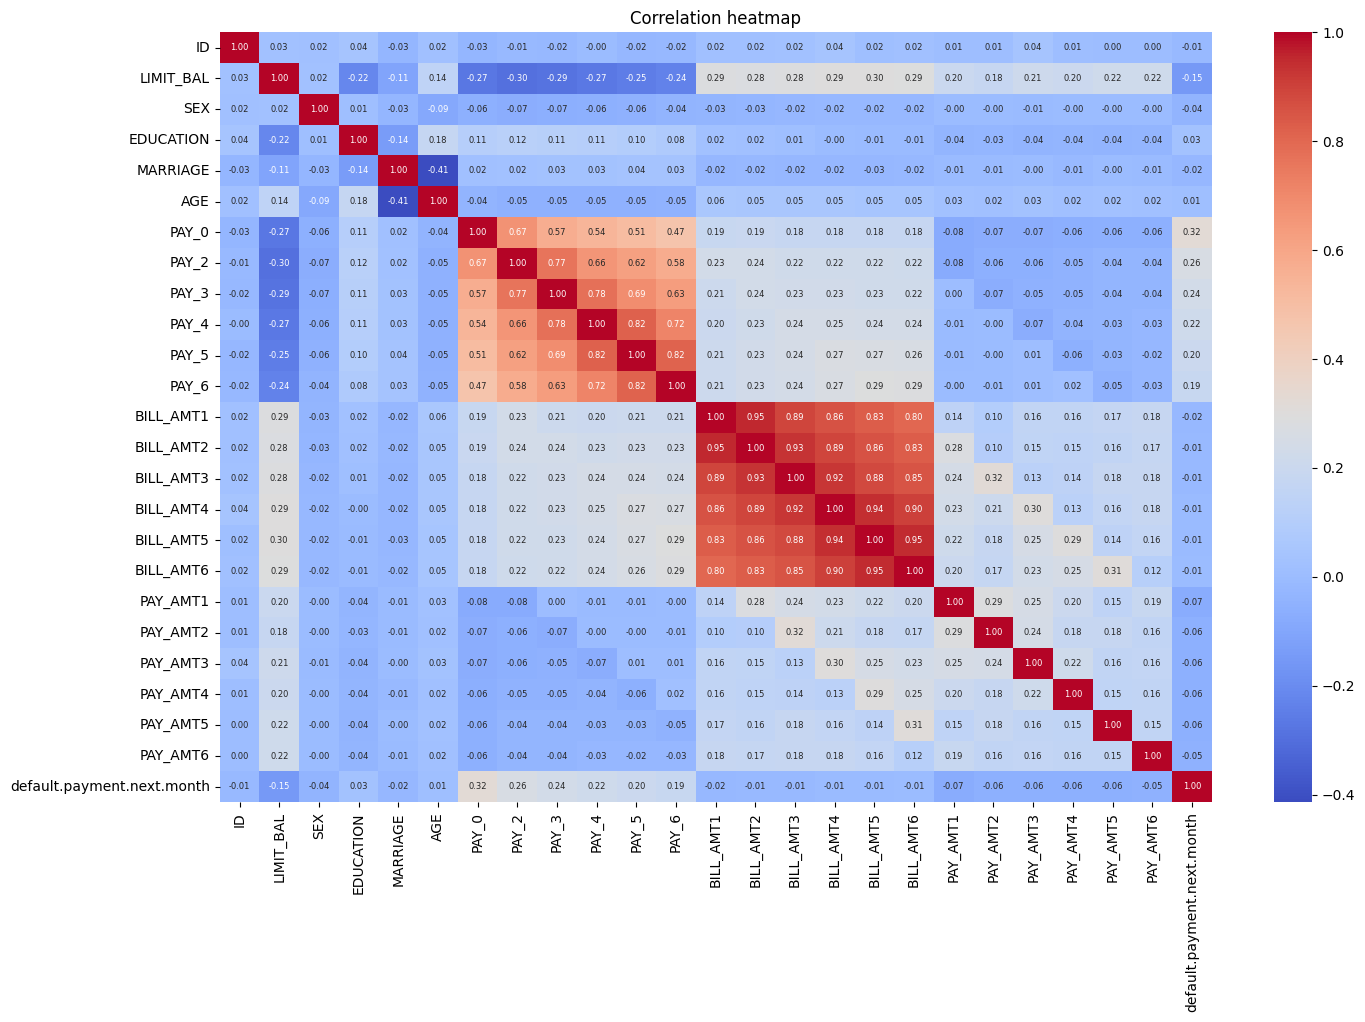

In [ ]:
plt.figure(figsize=(16, 10))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 6})
plt.title("Correlation heatmap")
plt.show()

## 🧹 Step 4: Clean the Data

- `ID` is only a row number. It carries no real information, so we **drop it** (the model should not learn from it).
- `EDUCATION` should be 1-4, but also contains 0, 5, 6 (undocumented). We group them into 4 = "others".
- `MARRIAGE` should be 1-3, but also contains 0. We group it into 3 = "others".
- All columns are already numeric, so no encoding is needed.

In [ ]:
df_clean = df.drop(columns=["ID"]).copy()

df_clean["EDUCATION"] = df_clean["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df_clean["MARRIAGE"] = df_clean["MARRIAGE"].replace({0: 3})

print("EDUCATION values:", sorted(df_clean["EDUCATION"].unique()))
print("MARRIAGE values: ", sorted(df_clean["MARRIAGE"].unique()))
print("Columns left:", df_clean.shape[1])

EDUCATION values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
MARRIAGE values:  [np.int64(1), np.int64(2), np.int64(3)]
Columns left: 24


## 🧪 Step 5: Train-Test Split

80% of rows for training, 20% for testing. `stratify=y` keeps the default rate the same in both parts.

In [ ]:
X = df_clean.drop(columns=[TARGET])
y = df_clean[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("\nTrain default rate: {:.1%}".format(y_train.mean()))
print("Test default rate:  {:.1%}".format(y_test.mean()))

X_train: (24000, 23) | X_test: (6000, 23)

Train default rate: 22.1%
Test default rate:  22.1%


## 📐 Step 6: Feature Scaling

`StandardScaler` converts each column to mean 0 and standard deviation 1.
It is **fitted on the training data only**, then reused on the test data (this avoids data leakage).

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled train mean (≈0):", X_train_scaled.mean().round(3))
print("Scaled train std  (≈1):", X_train_scaled.std().round(3))

Scaled train mean (≈0): 0.0
Scaled train std  (≈1): 1.0


## ⚙️ Step 7: Logistic Regression (the model used by the app)

In [ ]:
model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC: ", round(roc_auc_score(y_test, y_prob), 4))
print("\nClassification report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8083
ROC-AUC:  0.7079

Classification report:
              precision    recall  f1-score   support

           0       0.82      0.97      0.89      4673
           1       0.69      0.24      0.36      1327

    accuracy                           0.81      6000
   macro avg       0.75      0.61      0.62      6000
weighted avg       0.79      0.81      0.77      6000



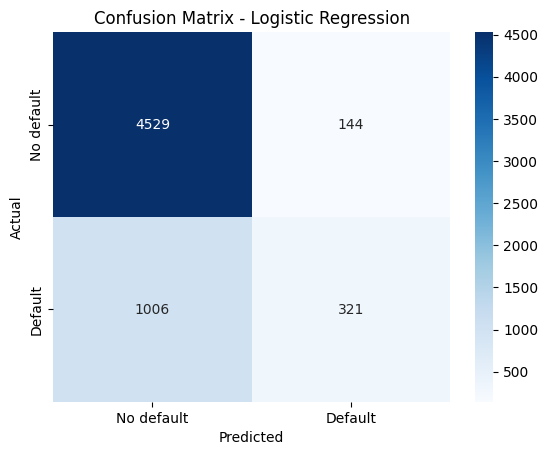

In [ ]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No default", "Default"],
            yticklabels=["No default", "Default"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

### Which features matter most?
Because the data is scaled, the weights (coefficients) are comparable.
Positive = pushes toward default, negative = pushes toward safe.

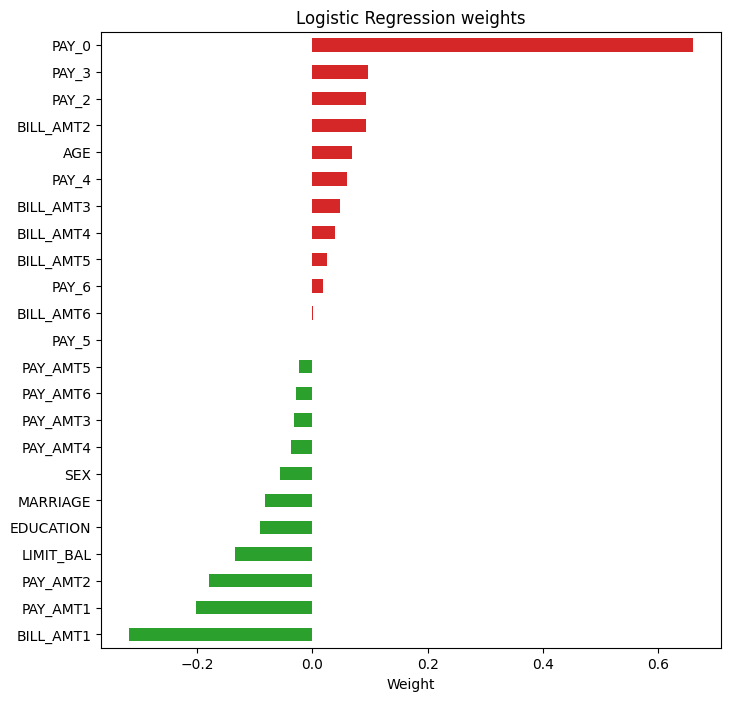

PAY_0        0.660694
PAY_3        0.097000
PAY_2        0.092795
BILL_AMT2    0.092520
AGE          0.069492
dtype: float64

In [ ]:
coef = pd.Series(model.coef_[0], index=X.columns).sort_values()

plt.figure(figsize=(8, 8))
coef.plot(kind="barh", color=["tab:green" if v < 0 else "tab:red" for v in coef])
plt.title("Logistic Regression weights")
plt.xlabel("Weight")
plt.show()

coef.sort_values(ascending=False).head(5)

## 🌳 Step 8: Decision Tree (comparison only)

Trees do not need scaling. `max_depth=5` stops it from memorising the training data.

In [ ]:
tree = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE)
tree.fit(X_train, y_train)

y_pred_tree = tree.predict(X_test)
y_prob_tree = tree.predict_proba(X_test)[:, 1]

print("Decision Tree accuracy:", round(accuracy_score(y_test, y_pred_tree), 4))
print("Decision Tree ROC-AUC: ", round(roc_auc_score(y_test, y_prob_tree), 4))
print("\nClassification report:")
print(classification_report(y_test, y_pred_tree))

Decision Tree accuracy: 0.8172
Decision Tree ROC-AUC:  0.7418

Classification report:
              precision    recall  f1-score   support

           0       0.84      0.95      0.89      4673
           1       0.66      0.35      0.46      1327

    accuracy                           0.82      6000
   macro avg       0.75      0.65      0.68      6000
weighted avg       0.80      0.82      0.80      6000



### Model comparison

In [ ]:
pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree (depth 5)"],
    "Accuracy": [accuracy_score(y_test, y_pred), accuracy_score(y_test, y_pred_tree)],
    "ROC-AUC": [roc_auc_score(y_test, y_prob), roc_auc_score(y_test, y_prob_tree)],
}).round(4)

,Model,Accuracy,ROC-AUC
0,Logistic Regression,0.8083,0.7079
1,Decision Tree (depth 5),0.8172,0.7418


## 💾 Step 9: Save for the Streamlit App

We save the **exact** model and scaler evaluated above, plus the column order the model expects.

In [ ]:
joblib.dump(model, "lr_model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(list(X.columns), "columns.pkl")

print("Saved: lr_model.pkl, scaler.pkl, columns.pkl")
print("Features the model expects (%d):" % X.shape[1])
print(list(X.columns))

Saved: lr_model.pkl, scaler.pkl, columns.pkl
Features the model expects (23):
['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']


### Sanity check: reload the files and predict one customer, like the app does

In [ ]:
m = joblib.load("lr_model.pkl")
s = joblib.load("scaler.pkl")
cols = joblib.load("columns.pkl")

sample = X_test.iloc[[0]][cols]
risk = m.predict_proba(s.transform(sample))[0, 1] * 100

print("Predicted default risk: {:.1f}%".format(risk))
print("Actual outcome:", "Default" if y_test.iloc[0] == 1 else "No default")

Predicted default risk: 10.8%
Actual outcome: No default
